<a href="https://colab.research.google.com/github/VictorFrank-enstein/PH1050-Climate-Project/blob/main/PH1050_Sashank_Task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from io import StringIO
from IPython.display import display

# Physical constants
S = 1361.0                 # Solar constant (W/m^2)
alpha = 0.30               # Planetary albedo
sigma = 5.67e-8            # Stefan-Boltzmann constant (W/m^2/K^4)

C1 = 2.0e8                 # Heat capacity (J/m^2/K)
C2 = 4.0e8

eps = 0.61                 # Atmospheric emissivity
seconds_per_year = 3.156e7

start_year = 1959
end_year = 2018

# print("Libraries imported successfully.")

In [ ]:
def Q_net(T, eps):
    incoming = S * (1 - alpha) / 4
    outgoing = eps * sigma * T**4
    return incoming - outgoing


def dTdt(T, eps, C):
    return Q_net(T, eps) / C


def bisection(eps, tol=1e-5):
    T_low = 200.0
    T_high = 350.0

    if Q_net(T_low, eps) * Q_net(T_high, eps) > 0:
        raise ValueError("The interval does not bracket an equilibrium.")

    while T_high - T_low > tol:
        T_mid = (T_low + T_high) / 2

        if Q_net(T_mid, eps) > 0:
            T_low = T_mid
        else:
            T_high = T_mid

    return (T_low + T_high) / 2


def simulate(eps, C, T0=250.0, years=60, dt_years=0.25, method="RK4"):
    n_float = years / dt_years

    if not np.isclose(n_float, round(n_float)):
        raise ValueError("Choose a time step that divides the total time.")

    n_steps = int(round(n_float))
    dt = dt_years * seconds_per_year

    time_years = np.arange(n_steps + 1) * dt_years
    T = np.zeros(n_steps + 1)
    T[0] = T0

    for i in range(n_steps):
        current_T = T[i]

        if method == "Euler":
            T[i + 1] = current_T + dt * dTdt(current_T, eps, C)

        elif method == "RK4":
            k1 = dTdt(current_T, eps, C)
            k2 = dTdt(current_T + dt * k1 / 2, eps, C)
            k3 = dTdt(current_T + dt * k2 / 2, eps, C)
            k4 = dTdt(current_T + dt * k3, eps, C)

            T[i + 1] = current_T + (dt / 6) * (k1 + 2*k2 + 2*k3 + k4)

        else:
            raise ValueError("Method must be 'Euler' or 'RK4'.")

    return time_years, T


# Checking the two equilibrium temperatures given in the project statement
print(f"Equilibrium for eps = 1.00: {bisection(1.0):.2f} K")
print(f"Equilibrium for eps = 0.61: {bisection(0.61):.2f} K")

Equilibrium for eps = 1.00: 254.58 K
Equilibrium for eps = 0.61: 288.07 K


Bisection equilibrium: 288.068531 K

C = 2.00e+08, method = Euler, final T = 288.068532 K, error = 9.046e-07 K
C = 2.00e+08, method = RK4, final T = 288.068532 K, error = 9.046e-07 K
C = 4.00e+08, method = Euler, final T = 288.068528 K, error = 3.526e-06 K
C = 4.00e+08, method = RK4, final T = 288.068525 K, error = 6.546e-06 K


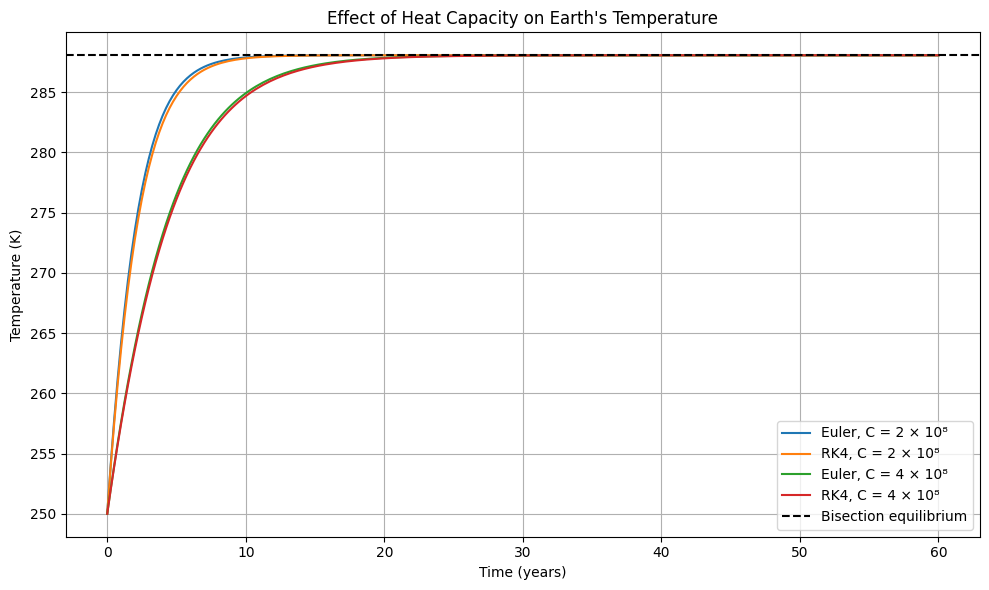

In [ ]:
T_equilibrium = bisection(eps)
C_values = [C1, C2]
methods = ["Euler", "RK4"]

results = {}

print(f"Bisection equilibrium: {T_equilibrium:.6f} K\n")

for C in C_values:
    for method in methods:
        t, T = simulate(
            eps=eps,
            C=C,
            T0=250.0,
            years=60,
            dt_years=0.25,
            method=method
        )

        results[(C, method)] = (t, T)
        error = abs(T[-1] - T_equilibrium)

        print(
            f"C = {C:.2e}, method = {method}, "
            f"final T = {T[-1]:.6f} K, error = {error:.3e} K"
        )

plt.figure(figsize=(10, 6))

for (C, method), (t, T) in results.items():
    plt.plot(t, T, label=f"{method}, C = {C/1e8:.0f} × 10⁸")

plt.axhline(T_equilibrium, color="black", linestyle="--", label="Bisection equilibrium")
plt.xlabel("Time (years)")
plt.ylabel("Temperature (K)")
plt.title("Effect of Heat Capacity on Earth's Temperature")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Reference temperature at 10 years: 287.8146970193 K

Observed orders (all step sizes):
Euler: 0.9037
RK4:   4.1085

Observed orders (four smallest step sizes):
Euler: 0.9676
RK4:   4.0438

Error table
Step size (years) | Euler error (K) | RK4 error (K)
         1.00000 | 2.17711904e-01 | 1.03308451e-03
         0.50000 | 1.34813718e-01 | 5.22983372e-05
         0.25000 | 7.36276029e-02 | 2.94604246e-06
         0.12500 | 3.83182912e-02 | 1.74839386e-07
         0.06250 | 1.95283155e-02 | 1.06475682e-08
         0.03125 | 9.85555295e-03 | 6.55688837e-10


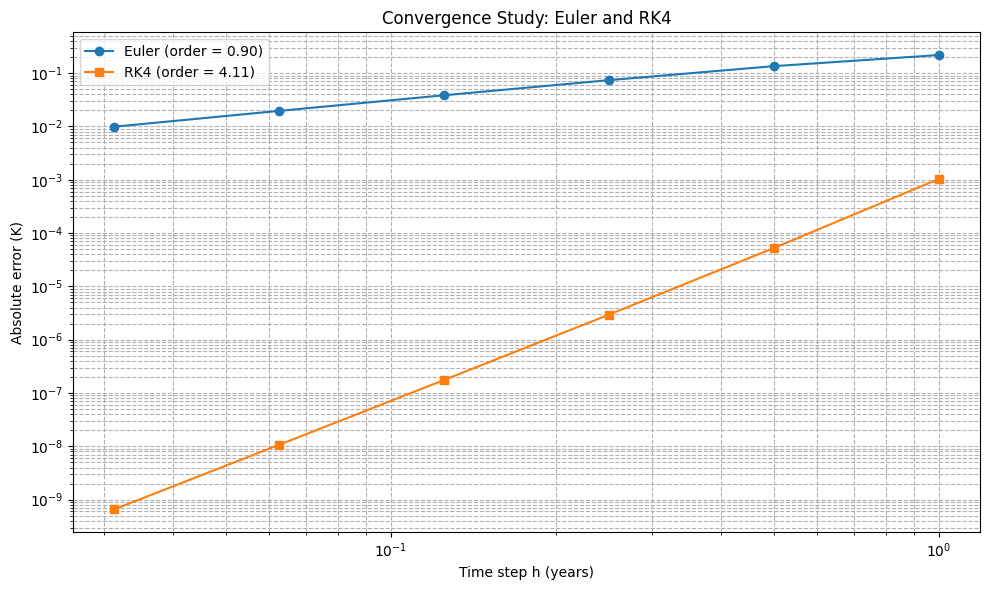

In [ ]:
C = C1
T0 = 250.0
final_years = 10

step_sizes = np.array([1.0, 0.5, 0.25, 0.125, 0.0625, 0.03125])

# Fine-step RK4 reference solution
reference_step = 1 / 4096
t_ref, T_ref = simulate(
    eps=eps,
    C=C,
    T0=T0,
    years=final_years,
    dt_years=reference_step,
    method="RK4"
)
T_reference = T_ref[-1]

print(f"Reference temperature at {final_years} years: {T_reference:.10f} K")

errors = {"Euler": [], "RK4": []}

for h in step_sizes:
    for method in ["Euler", "RK4"]:
        t, T = simulate(
            eps=eps,
            C=C,
            T0=T0,
            years=final_years,
            dt_years=h,
            method=method
        )

        errors[method].append(abs(T[-1] - T_reference))

# Fit the slope over all step sizes
order_euler = np.polyfit(
    np.log(step_sizes),
    np.log(errors["Euler"]), 1)[0]
order_rk4 = np.polyfit(
    np.log(step_sizes),
    np.log(errors["RK4"]), 1)[0]

# Calculate the slope using the four smallest time steps
order_euler_fine = np.polyfit(np.log(step_sizes[-4:]), np.log(errors["Euler"][-4:]), 1)[0]
order_rk4_fine = np.polyfit(np.log(step_sizes[-4:]), np.log(errors["RK4"][-4:]), 1)[0]

print("\nObserved orders (all step sizes):")
print(f"Euler: {order_euler:.4f}")
print(f"RK4:   {order_rk4:.4f}")

print("\nObserved orders (four smallest step sizes):")
print(f"Euler: {order_euler_fine:.4f}")
print(f"RK4:   {order_rk4_fine:.4f}")

print("\nError table")
print("Step size (years) | Euler error (K) | RK4 error (K)")
for i, h in enumerate(step_sizes):
    print(f"{h:16.5f} | {errors['Euler'][i]:.8e} | {errors['RK4'][i]:.8e}")

plt.figure(figsize=(10, 6))
plt.loglog(step_sizes, errors["Euler"], "o-", label=f"Euler (order = {order_euler:.2f})")
plt.loglog(step_sizes, errors["RK4"], "s-", label=f"RK4 (order = {order_rk4:.2f})")
plt.xlabel("Time step h (years)")
plt.ylabel("Absolute error (K)")
plt.title("Convergence Study: Euler and RK4")
plt.grid(True, which="both", linestyle="--")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
co2_path = Path("/content/co2_annmean_mlo.csv")

if not co2_path.exists():
    raise FileNotFoundError("Could not find co2_annmean_mlo.csv in the /content/ directory. Please ensure it is uploaded.")

print("Using file:", co2_path)

Using file: /content/co2_annmean_mlo.csv


In [ ]:
with open(co2_path, "r", encoding="utf-8-sig") as file:
    data_lines = [
        line for line in file
        if line.strip() and not line.lstrip().startswith("#")
    ]

co2_df = pd.read_csv(StringIO("".join(data_lines)))
co2_df.columns = co2_df.columns.str.strip().str.lower()

co2_df["year"] = pd.to_numeric(co2_df["year"], errors="coerce")
co2_df["mean"] = pd.to_numeric(co2_df["mean"], errors="coerce")

co2_df = co2_df[
    (co2_df["year"] >= start_year) & (co2_df["year"] <= end_year)
].sort_values("year").reset_index(drop=True)

missing_co2 = co2_df["mean"].isna().sum()
print("Missing CO₂ values:", missing_co2)

co2_df = co2_df.dropna(subset=["year", "mean"]).copy()
co2_df["year"] = co2_df["year"].astype(int)

if len(co2_df) != end_year - start_year + 1:
    raise ValueError("The CO₂ data do not contain every year from 1959 to 2018.")

if co2_df["year"].duplicated().any():
    raise ValueError("Duplicate years were found in the CO₂ data.")

print("Dataset loaded successfully.")
print("Columns:", co2_df.columns.tolist())
print("First year:", co2_df["year"].min())
print("Last year:", co2_df["year"].max())
print("Number of observations:", len(co2_df))

display(co2_df.head())
display(co2_df.tail())

Missing CO₂ values: 0
Dataset loaded successfully.
Columns: ['year', 'mean', 'unc']
First year: 1959
Last year: 2018
Number of observations: 60


,year,mean,unc
0,1959,315.98,0.12
1,1960,316.91,0.12
2,1961,317.64,0.12
3,1962,318.45,0.12
4,1963,318.99,0.12


,year,mean,unc
55,2014,398.81,0.12
56,2015,401.01,0.12
57,2016,404.41,0.12
58,2017,406.76,0.12
59,2018,408.72,0.12


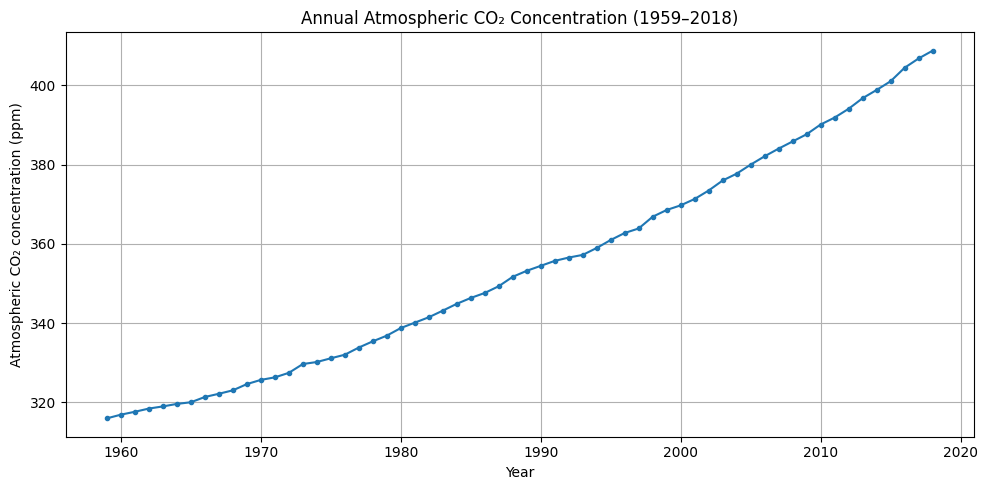

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(co2_df["year"], co2_df["mean"], marker="o", markersize=3)
plt.xlabel("Year")
plt.ylabel("Atmospheric CO₂ concentration (ppm)")
plt.title("Annual Atmospheric CO₂ Concentration (1959–2018)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
co2_years = co2_df["year"].to_numpy(dtype=float)
co2_values = co2_df["mean"].to_numpy(dtype=float)
c0 = co2_values[0]


def F_co2(year):
    if year < co2_years[0] or year > co2_years[-1]:
        raise ValueError("Year is outside the CO₂ data range.")

    concentration = np.interp(year, co2_years, co2_values)
    return 5.35 * np.log(concentration / c0)


print(f"Initial CO₂: {c0:.2f} ppm")
print(f"Initial forcing: {F_co2(start_year):.6f} W/m^2")
print(f"Final CO₂: {co2_values[-1]:.2f} ppm")
print(f"Final forcing: {F_co2(end_year):.6f} W/m^2")

Initial CO₂: 315.98 ppm
Initial forcing: 0.000000 W/m^2
Final CO₂: 408.72 ppm
Final forcing: 1.376830 W/m^2


In [ ]:
def dTdt_forced(T, year, eps, C):
    incoming = S * (1 - alpha) / 4
    outgoing = eps * sigma * T**4
    forcing = F_co2(year)

    return (incoming - outgoing + forcing) / C


def simulate_forced(eps, C, T0, start_year=1959, end_year=2018,
                    dt_years=0.25, method="RK4"):
    total_years = end_year - start_year
    n_float = total_years / dt_years

    if not np.isclose(n_float, round(n_float)):
        raise ValueError("Choose a time step that divides the total time.")

    n_steps = int(round(n_float))
    dt = dt_years * seconds_per_year

    time = start_year + np.arange(n_steps + 1) * dt_years
    T = np.zeros(n_steps + 1)
    T[0] = T0

    for i in range(n_steps):
        Ti = T[i]
        ti = time[i]

        if method == "Euler":
            k1 = dTdt_forced(Ti, ti, eps, C)
            T[i + 1] = Ti + dt * k1

        elif method == "RK4":
            k1 = dTdt_forced(Ti, ti, eps, C)
            k2 = dTdt_forced(Ti + dt*k1/2, ti + dt_years/2, eps, C)
            k3 = dTdt_forced(Ti + dt*k2/2, ti + dt_years/2, eps, C)
            k4 = dTdt_forced(Ti + dt*k3, ti + dt_years, eps, C)

            T[i + 1] = Ti + (dt / 6) * (k1 + 2*k2 + 2*k3 + k4)

        else:
            raise ValueError("Method must be 'Euler' or 'RK4'.")

    return time, T

In [ ]:
T0 = bisection(eps)
C = C1
dt_years = 0.25

time_euler, T_euler = simulate_forced(
    eps, C, T0, start_year, end_year, dt_years, "Euler"
)

time_rk4, T_rk4 = simulate_forced(
    eps, C, T0, start_year, end_year, dt_years, "RK4"
)

warming_euler = T_euler - T_euler[0]
warming_rk4 = T_rk4 - T_rk4[0]

print(f"Initial equilibrium temperature: {T0:.6f} K")
print(f"Euler warming in {end_year}: {warming_euler[-1]:.6f} K")
print(f"RK4 warming in {end_year}: {warming_rk4[-1]:.6f} K")
print(f"Difference between methods: {abs(warming_euler[-1] - warming_rk4[-1]):.3e} K")

Initial equilibrium temperature: 288.068531 K
Euler warming in 2018: 0.397899 K
RK4 warming in 2018: 0.397821 K
Difference between methods: 7.765e-05 K


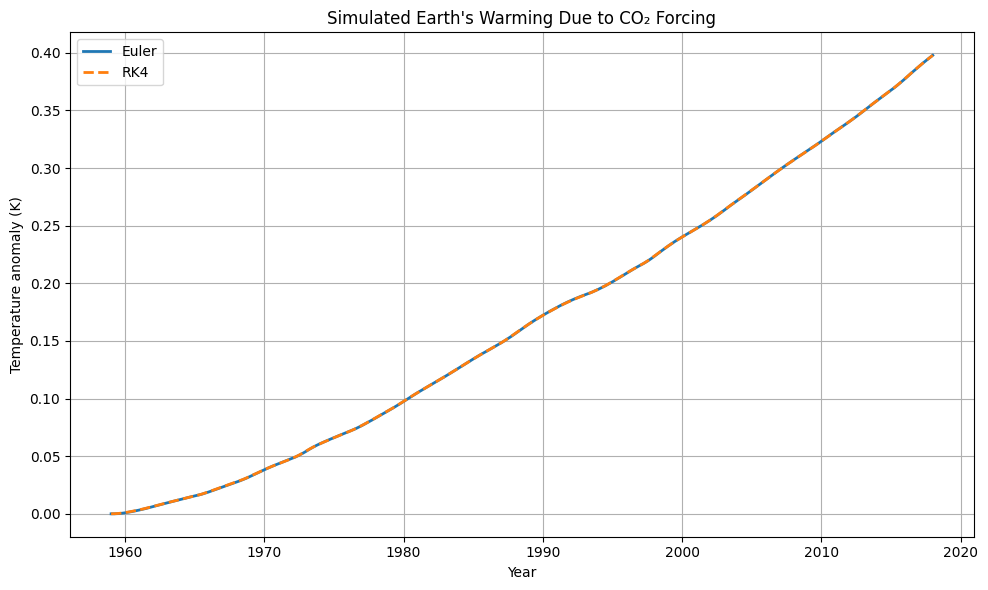

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(time_euler, warming_euler, label="Euler", linewidth=2)
plt.plot(time_rk4, warming_rk4, "--", label="RK4", linewidth=2)
plt.xlabel("Year")
plt.ylabel("Temperature anomaly (K)")
plt.title("Simulated Earth's Warming Due to CO₂ Forcing")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
annual_years = np.arange(start_year, end_year + 1)

annual_euler = np.interp(annual_years, time_euler, warming_euler)
annual_rk4 = np.interp(annual_years, time_rk4, warming_rk4)

results_df = pd.DataFrame({
    "Year": annual_years,
    "CO2_ppm": co2_values,
    "CO2_Forcing_W_m2": [F_co2(year) for year in annual_years],
    "Euler_Warming_K": annual_euler,
    "RK4_Warming_K": annual_rk4
})

output_path = Path("/content/Sashank_CO2_Simulation_Results.csv")
results_df.to_csv(output_path, index=False)

print("Simulation results saved to:", output_path)
display(results_df.head())
display(results_df.tail())

Simulation results saved to: /content/Sashank_CO2_Simulation_Results.csv


,Year,CO2_ppm,CO2_Forcing_W_m2,Euler_Warming_K,RK4_Warming_K
0,1959,315.98,0.000000,0.000000,0.000000
1,1960,316.91,0.015723,0.000853,0.001051
2,1961,317.64,0.028033,0.003192,0.003380
3,1962,318.45,0.041658,0.006195,0.006363
4,1963,318.99,0.050722,0.009428,0.009503


,Year,CO2_ppm,CO2_Forcing_W_m2,Euler_Warming_K,RK4_Warming_K
55,2014,398.81,1.245513,0.358574,0.358590
56,2015,401.01,1.274945,0.367602,0.367603
57,2016,404.41,1.320114,0.377415,0.377609
58,2017,406.76,1.351113,0.388088,0.388134
59,2018,408.72,1.376830,0.397899,0.397821
